# Injection-recovery with the analytic Baluev FAP, no signal fitted: HARPS-N and HARPS-N − SunSim

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import brentq
from scipy.special import gammaln
import cmasher as cmr

from sunsim import local_path, observations as obs
from sunsim.residuals import ResidualAnalysis

plt.rcParams.update({
    "figure.figsize": (15, 9), "font.size": 15, "axes.labelsize": 15, "axes.titlesize": 15, "xtick.labelsize": 15,
    "ytick.labelsize": 15, "legend.fontsize": 13, "axes.linewidth": 0.5, "xtick.direction": "in",
    "ytick.direction": "in", "xtick.top": True, "ytick.right": True, "lines.linewidth": 1.5, "lines.markersize": 3,
})

SIM_RV = os.path.join(local_path('personal_data'), 'rv-15.txt')
ORIGIN = '2015-07-18'                # t = 0 of the simulation
FIRST, LAST = '2015-07-18', '2024-01-28'
FIGURES = '/Users/sophiestucki/Documents/rv_opt/figures/final/'                       # folder where the PDFs are saved; None: not saved

FAP = 1e-3                           # detection threshold (analytic Baluev FAP)
PERIOD_TOL = 0.1                     # recovered period within 10 % of the injected one
EXCL_TOL = 0.1                       # injected periods flagged if a significant peak of the series is within 10 %
PERIODS_U = np.array([5, 10, 20, 50, 100, 150, 200, 300, 365, 425], dtype=float)   # injected periods [d]
AMPLITUDES = np.linspace(0.1, 0.5, 21)   # injected semi-amplitudes [m/s]
N_PHASES = 100                       # times of transit per (P, K)
YEAR = 365.25


def save(fig, name):
    if FIGURES:
        fig.savefig(os.path.join(FIGURES, name + '.pdf'), bbox_inches='tight', dpi=300)

## Data

In [2]:
t_s, rv_s = np.loadtxt(SIM_RV).T
window = (t_s >= obs.jd_of_date(FIRST) - obs.jd_of_date(ORIGIN)) & (t_s < obs.jd_of_date(LAST) - obs.jd_of_date(ORIGIN) + 1)
t_s, rv_s = t_s[window], rv_s[window]
harps = obs.load_harpsn(local_path('harpsn_sun'), ORIGIN, end=LAST, t_start=FIRST)
cuts = obs.load_interventions(local_path('harpsn_interventions'), ORIGIN)
rv = obs.compare_rv(harps, t_s, rv_s, interventions=cuts)

order = np.argsort(rv['t'], kind='stable')
T = np.asarray(rv['t'], dtype=float)[order]
G = np.asarray(rv['period'])[order]
Y_OBS = np.asarray(rv['obs'], dtype=float)[order]          # HARPS-N, median of every interval removed below
for g in np.unique(G):
    Y_OBS[G == g] -= np.median(Y_OBS[G == g])
Y_RES = np.asarray(rv['res'], dtype=float)[order]          # HARPS-N - SunSim, median of every interval removed
ERR = np.asarray(rv['obs_err'], dtype=float)[order]                   # daily uncertainty of HARPS-N [m/s]
print('%d days, %d intervals, %.0f d; daily uncertainty: median %.2f m/s, 5-95 %% %.2f-%.2f m/s, %d day(s) without '
      '(set to the median)' % (len(T), len(np.unique(G)), np.ptp(T), np.nanmedian(ERR), *np.nanpercentile(ERR, [5, 95]),
                               (~np.isfinite(ERR)).sum()))
ERR = np.where(np.isfinite(ERR), ERR, np.nanmedian(ERR))

1984 days, 21 intervals, 3101 d; daily uncertainty: median 0.49 m/s, 5-95 % 0.34-0.72 m/s, 1 day(s) without (set to the median)


## Model: GLS with a constant and the Baluev FAP

In [3]:
def baluev_fap(z, N, d_H, fmax, t, w=None):
    # Baluev (2008) eq. 6 (astropy method='baluev', normalisation 'standard'), base model of d_H linear parameters.
    # z: power (ZK); fmax: highest frequency searched [1/d]; w: weights (None: equal), for the variance of t as astropy.
    z = np.clip(np.asarray(z, dtype=np.float64), 0, 1)
    NH, NK = N - d_H, N - d_H - 2
    fap1 = (1 - z) ** (0.5 * NK)
    gamma = np.sqrt(2 / NH) * np.exp(gammaln(NH / 2) - gammaln((NH - 1) / 2))
    w = np.full(len(t), 1 / len(t)) if w is None else np.asarray(w) / np.sum(w)
    W = fmax * np.sqrt(4 * np.pi * (w @ (t - w @ t) ** 2))
    tau = gamma * W * (1 - z) ** (0.5 * (NK - 1)) * np.sqrt(0.5 * NH * z)
    out = -np.expm1(-tau) + fap1 * np.exp(-tau)
    return out if out.ndim else float(out)


class Baluev(ResidualAnalysis):
    # GLS of ResidualAnalysis (constant + sinusoid, equal weights) with the Baluev (2008) FAP, d_H = 1

    def fap(self, power):
        return baluev_fap(power, self.N, 1, self.freq[-1], self.t, self.w)

    def power_level(self, fap):
        return brentq(lambda z: np.log(max(self.fap(z), 1e-300)) - np.log(fap), 1e-9, 1 - 1e-9)


def spectrum(ra):
    power, a, b, _ = ra._gls(ra.y)
    return {'P': 1 / ra.freq, 'power': power, 'amp': np.hypot(a, b)}


def local_peaks(ra, sp, fap=FAP):
    # every local maximum of sp with Baluev FAP <= fap, from the strongest
    p = sp['power']
    k = np.flatnonzero((p[1:-1] > p[:-2]) & (p[1:-1] >= p[2:])) + 1
    k = k[p[k] >= ra.power_level(fap)]
    k = k[np.argsort(-p[k])]
    return pd.DataFrame({'P [d]': sp['P'][k], 'K [m/s]': sp['amp'][k], 'power': p[k], 'FAP': ra.fap(p[k])})


def show(df, title, fmt=None):
    # plain-text table (copy-paste): fmt = {column: format}, other floats with 2 decimals, NaN as '-'
    fmt = fmt or {}
    print(title)
    print(df.to_string(formatters={c: (lambda f: lambda v: '-' if v != v else f % v)(fmt[c]) for c in fmt},
                       float_format=lambda v: '%.2f' % v, na_rep='-'))
    print()


SERIES = {'obs': ('HARPS-N', Y_OBS, obs.COLOURS['harpsn']), 'res': ('HARPS-N $-$ SunSim', Y_RES, obs.COLOURS['res'])}
models = {k: Baluev(T, y, groups=G, name=name) for k, (name, y, _) in SERIES.items()}
spectra = {k: spectrum(ra) for k, ra in models.items()}

## Periodograms

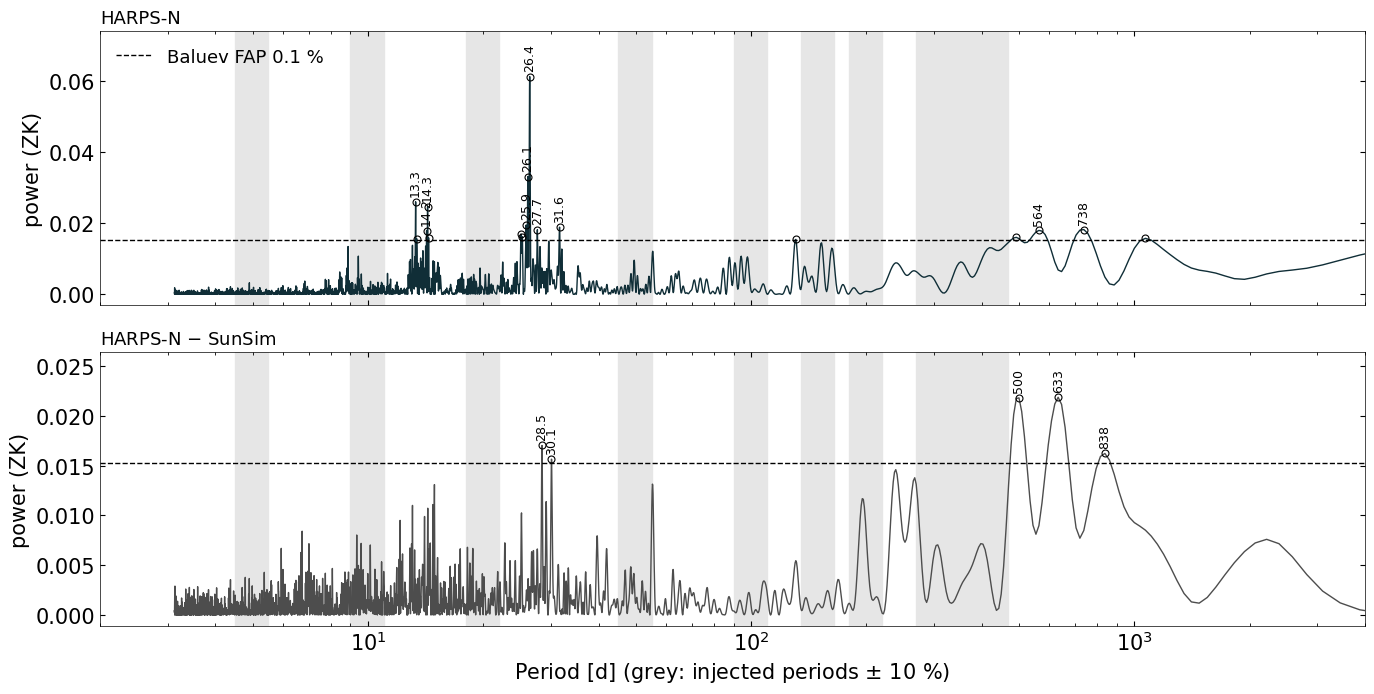

HARPS-N: significant peaks (Baluev FAP <= 0.001); injected periods within 10 % of one: none
    P [d] K [m/s]  power     FAP
0    26.4   0.492 0.0614 4.8e-24
1    26.1   0.363 0.0332 1.8e-11
2    13.3   0.320 0.0261 2.3e-08
3    14.3   0.317 0.0247 8.7e-08
4    25.9   0.281 0.0195 1.5e-05
5    31.6   0.273 0.0189 2.7e-05
6   738.3   0.257 0.0182 5.3e-05
7    27.7   0.270 0.0182 5.6e-05
8   563.8   0.264 0.0180 6.7e-05
9    14.2   0.268 0.0180 7.0e-05
10   25.1   0.263 0.0170 1.8e-04
11   25.3   0.256 0.0162 3.9e-04
12  492.2   0.257 0.0161 4.5e-04
13   14.4   0.251 0.0159 5.1e-04
14 1069.3   0.245 0.0158 6.0e-04
15   13.4   0.250 0.0157 6.5e-04
16  130.8   0.249 0.0155 8.0e-04

HARPS-N - SunSim: significant peaks (Baluev FAP <= 0.001); injected periods within 10 % of one: none
  P [d] K [m/s]  power     FAP
0 632.9   0.163 0.0219 1.5e-06
1 500.2   0.161 0.0218 1.6e-06
2  28.5   0.145 0.0170 1.8e-04
3 838.1   0.147 0.0162 3.9e-04
4  30.1   0.141 0.0156 6.8e-04



In [4]:
peaks, flag = {}, {}
fig, axes = plt.subplots(len(models), 1, figsize=(14, 3.6 * len(models)), sharex=True)
for ax, (k, ra) in zip(axes, models.items()):
    sp, colour = spectra[k], SERIES[k][2]
    peaks[k] = local_peaks(ra, sp)
    P_peak = peaks[k]['P [d]'].to_numpy()
    flag[k] = (np.abs(P_peak[None, :] - PERIODS_U[:, None]) / PERIODS_U[:, None] <= EXCL_TOL).any(axis=1)
    ax.plot(sp['P'], sp['power'], color=colour, lw=1)
    ax.axhline(ra.power_level(FAP), color='k', lw=1, ls='--', label='Baluev FAP %g %%' % (100 * FAP))
    ax.plot(peaks[k]['P [d]'], peaks[k]['power'], 'o', mfc='none', mec='k', ms=5, mew=0.8)
    for P, p in zip(peaks[k]['P [d]'][:10], peaks[k]['power'][:10]):
        ax.annotate('%.1f' % P if P < 100 else '%.0f' % P, (P, p), xytext=(0, 4), textcoords='offset points',
                    fontsize=9, rotation=90, ha='center', va='bottom')
    for P in PERIODS_U:
        ax.axvspan(P * (1 - EXCL_TOL), P * (1 + EXCL_TOL), color='0.9', zorder=0)
    ax.set_ylim(top=ax.get_ylim()[1] * 1.15)
    ax.set_title(ra.name, loc='left', fontsize=13)
    ax.set_ylabel('power (ZK)')
    ax.set_xscale('log')
    ax.set_xlim(2, 4000)
axes[0].legend(frameon=False, loc='upper left')
axes[-1].set_xlabel('Period [d] (grey: injected periods $\\pm$ %.0f %%)' % (100 * EXCL_TOL))
fig.tight_layout()
save(fig, 'gls_harpsn_corrected')
plt.show()
for k, ra in models.items():
    show(peaks[k], '%s: significant peaks (Baluev FAP <= %g); injected periods within %.0f %% of one: %s'
         % (ra.name.replace('$-$', '-'), FAP, 100 * EXCL_TOL, PERIODS_U[flag[k]] if flag[k].any() else 'none'),
         {'P [d]': '%.1f', 'K [m/s]': '%.3f', 'power': '%.4f', 'FAP': '%.1e'})

## Injection-recovery

In [5]:
rate = {}
for k, ra in models.items():
    ra.inject(PERIODS_U, AMPLITUDES, n_phases=N_PHASES, fap=FAP, fit=False, before=False, verbose=False)
    rate[k] = ra.detection_rate(period_tol=PERIOD_TOL)
    print('%-20s power at FAP %g: %.4f' % (ra.name.replace('$-$', '-'), FAP, ra.power_level(FAP)))

HARPS-N              power at FAP 0.001: 0.0152
HARPS-N - SunSim     power at FAP 0.001: 0.0152


## False detections

In [6]:
# false detection: FAP <= FAP and period within PERIOD_TOL of the injected one, but the recovered frequency is within
# 1/T of a significant peak of the series without planet and further than 1/T from the injected frequency
fp, alone, closest = {}, {}, {}
for k, ra in models.items():
    inj = ra.injection
    P_noise = peaks[k]['P [d]'].to_numpy()
    P_inj = PERIODS_U[:, None, None]
    f_rec, df = 1 / inj['P'], 1 / ra.tbase
    det = (inj['fap'] <= FAP) & (np.abs(inj['P'] - P_inj) / P_inj <= PERIOD_TOL)
    from_noise = (np.abs(f_rec[..., None] - 1 / P_noise) <= df).any(axis=-1) & (np.abs(f_rec - 1 / P_inj) > df)
    fp[k] = 100 * (det & from_noise).mean(axis=2).T                     # (n_amplitudes, n_periods)
    top = P_noise[0] if len(P_noise) else np.nan                         # highest peak without planet, if significant
    alone[k] = np.abs(top - PERIODS_U) / PERIODS_U <= PERIOD_TOL         # detected at that period with no planet
    j = np.argmin(np.abs(1 / P_noise[None, :] - 1 / PERIODS_U[:, None]), axis=1)   # closest significant peak (frequency)
    closest[k] = pd.DataFrame({'closest peak [d]': P_noise[j],
                               '|dP| / P [%]': 100 * np.abs(P_noise[j] - PERIODS_U) / PERIODS_U,
                               '|df| T': np.abs(1 / P_noise[j] - 1 / PERIODS_U) * ra.tbase,
                               'its FAP': peaks[k]['FAP'].to_numpy()[j]}, index=PERIODS_U.astype(int))

for k, ra in models.items():
    show(closest[k].assign(**{'without planet': np.where(alone[k], 'detected', '-'),
                              'false det. max [%]': fp[k].max(axis=0),
                              'false det. K=%.2f [%%]' % AMPLITUDES[0]: fp[k][0]}).rename_axis('P [d]'),
         '%s (|df| T < 1: closest peak not resolved from the injected period)' % ra.name.replace('$-$', '-'),
         {'closest peak [d]': '%.1f', '|dP| / P [%]': '%.1f', '|df| T': '%.2f', 'its FAP': '%.1e',
          'false det. max [%]': '%.0f', 'false det. K=%.2f [%%]' % AMPLITUDES[0]: '%.0f'})

HARPS-N (|df| T < 1: closest peak not resolved from the injected period)
      closest peak [d] |dP| / P [%] |df| T its FAP without planet false det. max [%] false det. K=0.10 [%]
P [d]                                                                                                     
5                 13.3        166.4 387.40 2.3e-08              -                  0                     0
10                13.3         33.2  77.30 2.3e-08              -                  0                     0
20                25.1         25.4  31.45 1.8e-04              -                  0                     0
50                31.6         36.7  35.98 2.7e-05              -                  0                     0
100              130.8         30.8   7.31 8.0e-04              -                  0                     0
150              130.8         12.8   3.03 8.0e-04              -                  0                     0
200              130.8         34.6   8.19 8.0e-04              -      

## Recovery maps

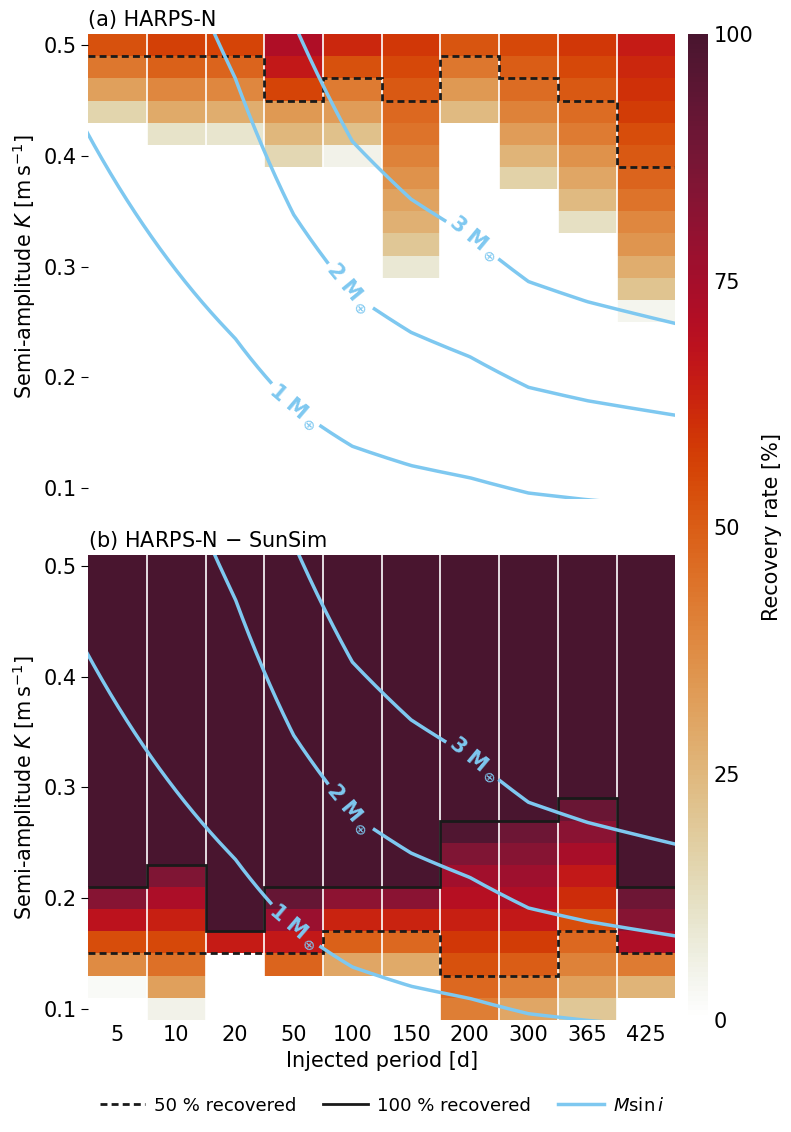

In [19]:
M_EARTH_1YR = (2 * np.pi * 6.674e-11 / (365.25 * 86400)) ** (1 / 3) * 5.972e24 / 1.989e30 ** (2 / 3)   # 0.0895 m/s
CMAP = cmr.get_sub_cmap('cmr.sunburst_r', 0.0, 0.8)                  # light: not recovered, dark red: 100 %
INK = '#1a1a1a'
ACCENT = '#7ec8f0'                                                     # M sin i curves
MASSES = {1: 50, 2: 95, 3: 205}                                        # M sin i [M_Earth]: period of its label
kmass = lambda m, p: m * M_EARTH_1YR * (p / 365.25) ** (-1 / 3)      # K of M sin i = m M_Earth
dk = AMPLITUDES[1] - AMPLITUDES[0]
edges_k = np.append(AMPLITUDES - dk / 2, AMPLITUDES[-1] + dk / 2)

# equal-width columns: the axis is log in P between consecutive injected periods
_lx, _ix = np.log(PERIODS_U), np.arange(len(PERIODS_U), dtype=float)
LX = np.r_[-30, _lx, 30]
IX = np.r_[_ix[0] - (_lx[0] + 30) / (_lx[1] - _lx[0]), _ix, _ix[-1] + (30 - _lx[-1]) / (_lx[-1] - _lx[-2])]
fwd = lambda p: np.interp(np.log(np.clip(p, 1e-12, None)), LX, IX)
inv = lambda x: np.exp(np.interp(x, IX, LX))
edges_p = inv(np.arange(len(PERIODS_U) + 1) - 0.5)
p_fine = np.geomspace(0.1, edges_p[-1] * 1.01, 2000)                # M sin i curves up to the plot borders


def label_curve(ax, line, x, text, gap=4, **kw):
    # bold text centred on line at x, along its slope; the line is cut under the text
    xd, yd = (np.asarray(v, float) for v in line.get_data())
    y = np.interp(x, xd, yd)
    (x0, y0), (x1, y1) = ax.transData.transform([(xd[i], yd[i]) for i in np.searchsorted(xd, x) + np.array([-3, 3])])
    t = ax.annotate(text, (x, y), ha='center', va='center', color=line.get_color(), fontweight='bold',
                    rotation_mode='anchor', zorder=line.get_zorder() + 1, **kw)
    r = 0.5 * t.get_window_extent(ax.figure.canvas.get_renderer()).width + gap
    t.set_rotation(np.degrees(np.arctan2(y1 - y0, x1 - x0)))
    d = ax.transData.transform(np.c_[xd, yd]) - ax.transData.transform((x, y))
    line.set_ydata(np.where(np.hypot(*d.T) < r, np.nan, yd))


def k_limit(rate, level):
    # lowest K above which every K of the grid reaches level % (NaN: never)
    out = np.full(rate.shape[1], np.nan)
    for j in range(rate.shape[1]):
        bad = np.flatnonzero(rate[:, j] < level)
        if len(bad) == 0:
            out[j] = AMPLITUDES[0]
        elif bad[-1] < len(AMPLITUDES) - 1:
            out[j] = AMPLITUDES[bad[-1] + 1]
    return out


def plot_recovery(panels, name):
    # panels: list of (rate (n_amplitudes, n_periods), title)
    with plt.rc_context({'xtick.direction': 'out', 'ytick.direction': 'out', 'xtick.top': False, 'ytick.right': False,
                         'xtick.major.size': 5, 'ytick.major.size': 5, 'axes.linewidth': 0.8}):
        n = len(panels)
        fig = plt.figure(figsize=(8, 6.4 * n))
        gs = fig.add_gridspec(n, 2, width_ratios=[1, 0.035], hspace=0.12, wspace=0.04)
        axes = [fig.add_subplot(gs[0, 0])]
        axes += [fig.add_subplot(gs[i, 0], sharex=axes[0], sharey=axes[0]) for i in range(1, n)]
        cax = fig.add_subplot(gs[:, 1])
        curves = {}
        for ax, (r, title) in zip(axes, panels):
            ax.set_xscale('function', functions=(fwd, inv))
            im = ax.pcolormesh(edges_p, edges_k, r, cmap=CMAP, vmin=0, vmax=100, rasterized=True)
            ax.vlines(edges_p[1:-1], edges_k[0], edges_k[-1], color='white', lw=1.2, zorder=2)   # column gaps
            for level, ls in ((50, (0, (2.5, 1.5))), (100, '-')):          # lower edge of the cells above level
                ax.stairs(k_limit(r, level) - dk / 2, edges_p, baseline=None, color=INK, lw=2, ls=ls, zorder=4)
            curves[ax] = {m: ax.plot(p_fine, kmass(m, p_fine), color=ACCENT, lw=2.5, zorder=5)[0] for m in MASSES}
            ax.set_title(title, loc='left', pad=6)
            ax.set_xticks(PERIODS_U, ['%.0f' % p for p in PERIODS_U])
            ax.xaxis.set_minor_locator(plt.NullLocator())
            ax.tick_params(axis='x', length=0, pad=4)
            ax.set_ylabel('Semi-amplitude $K$ [$\\mathrm{m\\,s^{-1}}$]')
            ax.set_ylim(edges_k[0], edges_k[-1])
            ax.set_yticks(np.arange(0.1, 0.51, 0.1))
            for s in ax.spines.values():
                s.set_visible(False)
        axes[0].set_xlim(edges_p[0], edges_p[-1])
        for ax in axes:                                                  # label on every curve, along its slope
            for m, p in MASSES.items():
                label_curve(ax, curves[ax][m], p, '%d M$_\\oplus$' % m, fontsize=15)
        axes[-1].set_xlabel('Injected period [d]')
        for ax in axes[:-1]:
            plt.setp(ax.get_xticklabels(), visible=False)
        cb = fig.colorbar(im, cax=cax, ticks=(0, 25, 50, 75, 100))
        cb.set_label('Recovery rate [%]', labelpad=6)
        cb.outline.set_visible(False)
        cax.tick_params(length=0, pad=4)
        handles = [Line2D([], [], color=INK, ls=(0, (2.5, 1.5)), lw=2), Line2D([], [], color=INK, lw=2),
                   Line2D([], [], color=ACCENT, lw=2.5)]
        labels = ['50 % recovered', '100 % recovered', '$M \\sin i$']
        axes[-1].legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=len(handles),
                       frameon=False, borderaxespad=0, handlelength=2.5, handletextpad=0.5, columnspacing=1.5)
    save(fig, name)
    plt.show()


plot_recovery([(rate[k], '(%s) %s' % (letter, models[k].name)) for letter, k in zip('ab', models)],
              'inj_baluev_harpsn_corrected')
if any(fp[k].any() for k in models):
    plot_recovery([(rate[k] - fp[k], '(%s) %s, equal weights, no false det.' % (letter, models[k].name))
                   for letter, k in zip('ab', models)], 'inj_baluev_harpsn_corrected_no_fp')

## Results

In [8]:
any_fp = any(fp[k].any() for k in models)
for k, ra in models.items():
    cols = {}
    for level in (50, 100):
        lim = k_limit(rate[k], level)
        cols['K %d%% [m/s]' % level] = lim
        cols['Msini %d%% [M_E]' % level] = lim / kmass(1, PERIODS_U)
    if any_fp:
        for level in (50, 100):
            cols['K %d%% no false det. [m/s]' % level] = k_limit(rate[k] - fp[k], level)
        cols['false det. max [%]'] = fp[k].max(axis=0)
    cols['closest peak [d]'] = closest[k]['closest peak [d]'].to_numpy()
    cols['|df| T'] = closest[k]['|df| T'].to_numpy()
    show(pd.DataFrame(cols, index=pd.Index(PERIODS_U.astype(int), name='P [d]')),
         '%s (-: 100 %% not reached up to K = %.1f m/s; |df| T < 1: closest peak not resolved)'
         % (ra.name.replace('$-$', '-'), AMPLITUDES[-1]),
         {'closest peak [d]': '%.1f', 'Msini 50% [M_E]': '%.1f', 'Msini 100% [M_E]': '%.1f'})


HARPS-N (-: 100 % not reached up to K = 0.5 m/s; |df| T < 1: closest peak not resolved)
       K 50% [m/s] Msini 50% [M_E]  K 100% [m/s] Msini 100% [M_E] closest peak [d]  |df| T
P [d]                                                                                     
5             0.50             1.3             -                -             13.3  387.40
10            0.50             1.7             -                -             13.3   77.30
20            0.50             2.1             -                -             25.1   31.45
50            0.46             2.7             -                -             31.6   35.98
100           0.48             3.5             -                -            130.8    7.31
150           0.46             3.8             -                -            130.8    3.03
200           0.50             4.6             -                -            130.8    8.19
300           0.48             5.0             -                -            492.2    4.04
36

## Accuracy of the recovered period and semi-amplitude

HARPS-N: recovered - injected, all K and phases recovered
       n rec. P grid step [%] dP/P [%] med dP/P [%] spread dK [m/s] med dK [m/s] spread dK/K [%] med dK/K [%] spread
P [d]                                                                                                               
5         144            0.02         0.00            0.00        0.051           0.016         10.6             3.4
10        185            0.03         0.00            0.00        0.074           0.026         16.1             5.6
20        181            0.06        -0.03            0.03        0.061           0.020         12.9             4.6
50        268            0.16        -0.29            0.32        0.069           0.029         14.6             6.7
100       217            0.32        -0.61            0.32        0.068           0.022         14.5             5.3
150       419            0.48         0.85            0.24        0.176           0.050         40.1            15.6
200   

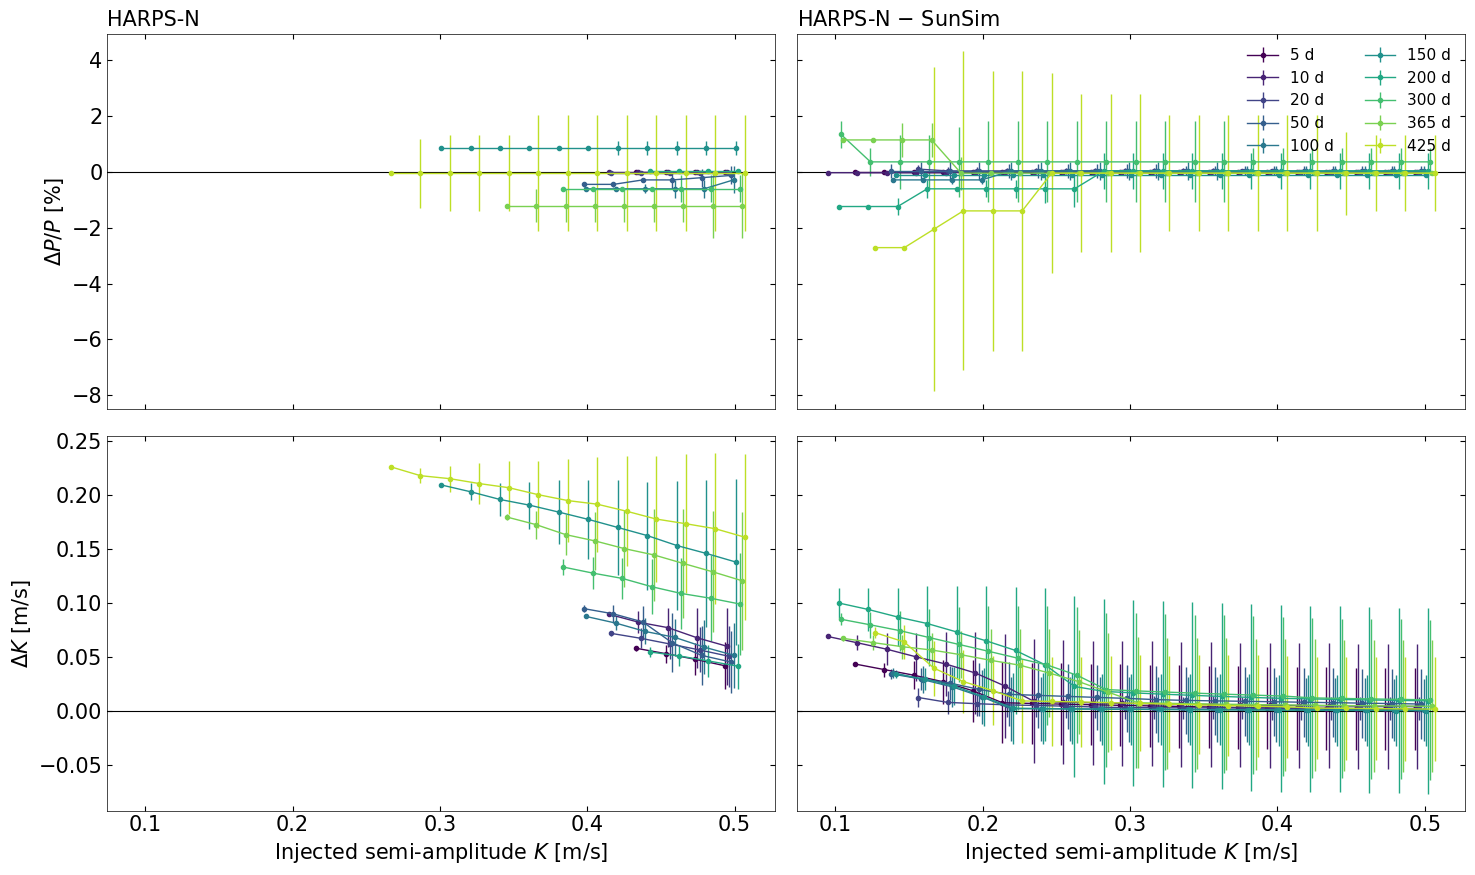

In [15]:
import warnings

# recovered values: GLS highest peak (inject with fit=False) of the injections counted as recovered
# (FAP <= FAP and period within PERIOD_TOL of the injected one); spread = half the 16-84 % range
acc = {}
for k, ra in models.items():
    inj = ra.injection
    P_inj, K_inj = PERIODS_U[:, None, None], AMPLITUDES[None, :, None]
    rec = (inj['fap'] <= FAP) & (np.abs(inj['P'] - P_inj) / P_inj <= PERIOD_TOL)
    acc[k] = {'dP': np.where(rec, 100 * (inj['P'] - P_inj) / P_inj, np.nan),          # [%] (n_P, n_K, n_phases)
              'dK': np.where(rec, inj['amp'] - K_inj, np.nan)}                         # [m/s]
    acc[k]['dK%'] = 100 * acc[k]['dK'] / K_inj


def stats(x, axis):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)                  # nothing recovered: NaN
        lo, med, hi = np.nanpercentile(x, [16, 50, 84], axis=axis)
    return med, (hi - lo) / 2


for k, ra in models.items():
    a = acc[k]
    flat = lambda v: v.reshape(len(PERIODS_U), -1)                       # all K and phases of every period
    cols = {'n rec.': np.isfinite(flat(a['dP'])).sum(axis=1),
            'P grid step [%]': 100 * PERIODS_U * (ra.freq[1] - ra.freq[0])}
    for name, key in (('dP/P [%]', 'dP'), ('dK [m/s]', 'dK'), ('dK/K [%]', 'dK%')):
        med, sig = stats(flat(a[key]), 1)
        cols[name + ' med'], cols[name + ' spread'] = med, sig
    show(pd.DataFrame(cols, index=pd.Index(PERIODS_U.astype(int), name='P [d]')),
         '%s: recovered - injected, all K and phases recovered' % ra.name.replace('$-$', '-'),
         {'P grid step [%]': '%.2f', 'dP/P [%] med': '%.2f', 'dP/P [%] spread': '%.2f', 'dK [m/s] med': '%.3f',
          'dK [m/s] spread': '%.3f', 'dK/K [%] med': '%.1f', 'dK/K [%] spread': '%.1f'})
    flat = lambda v: np.moveaxis(v, 1, 0).reshape(len(AMPLITUDES), -1)  # all periods and phases of every K
    cols = {'n rec.': np.isfinite(flat(a['dP'])).sum(axis=1)}
    for name, key in (('|dP|/P [%]', 'dP'), ('dK [m/s]', 'dK'), ('dK/K [%]', 'dK%')):
        med, sig = stats(np.abs(flat(a[key])) if key == 'dP' else flat(a[key]), 1)
        cols[name + ' med'], cols[name + ' spread'] = med, sig
    show(pd.DataFrame(cols, index=pd.Index(AMPLITUDES, name='K [m/s]')),
         '%s: recovered - injected, all periods and phases recovered' % ra.name.replace('$-$', '-'),
         {'|dP|/P [%] med': '%.2f', '|dP|/P [%] spread': '%.2f', 'dK [m/s] med': '%.3f', 'dK [m/s] spread': '%.3f',
          'dK/K [%] med': '%.1f', 'dK/K [%] spread': '%.1f'})

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True, sharey='row')
colours = plt.get_cmap('viridis')(np.linspace(0, 0.9, len(PERIODS_U)))
for col, (k, ra) in enumerate(models.items()):
    for row, key in enumerate(('dP', 'dK')):
        ax = axes[row, col]
        for i, P in enumerate(PERIODS_U):
            med, sig = stats(acc[k][key][i], 1)
            ax.errorbar(AMPLITUDES + (i - 4.5) * 0.0015, med, sig, fmt='o-', ms=3, lw=1, capsize=0,
                        color=colours[i], label='%.0f d' % P)
        ax.axhline(0, color='k', lw=0.8)
    axes[0, col].set_title(ra.name, loc='left')
axes[0, 0].set_ylabel('$\\Delta P / P$ [%]')
axes[1, 0].set_ylabel('$\\Delta K$ [$\\mathrm{m\\,s^{-1}}$]')
for ax in axes[1]:
    ax.set_xlabel('Injected semi-amplitude $K$ [$\\mathrm{m\\,s^{-1}}$]')
axes[0, 1].legend(ncols=2, fontsize=11, frameon=False)
fig.tight_layout()
save(fig, 'inj_baluev_accuracy')
plt.show()


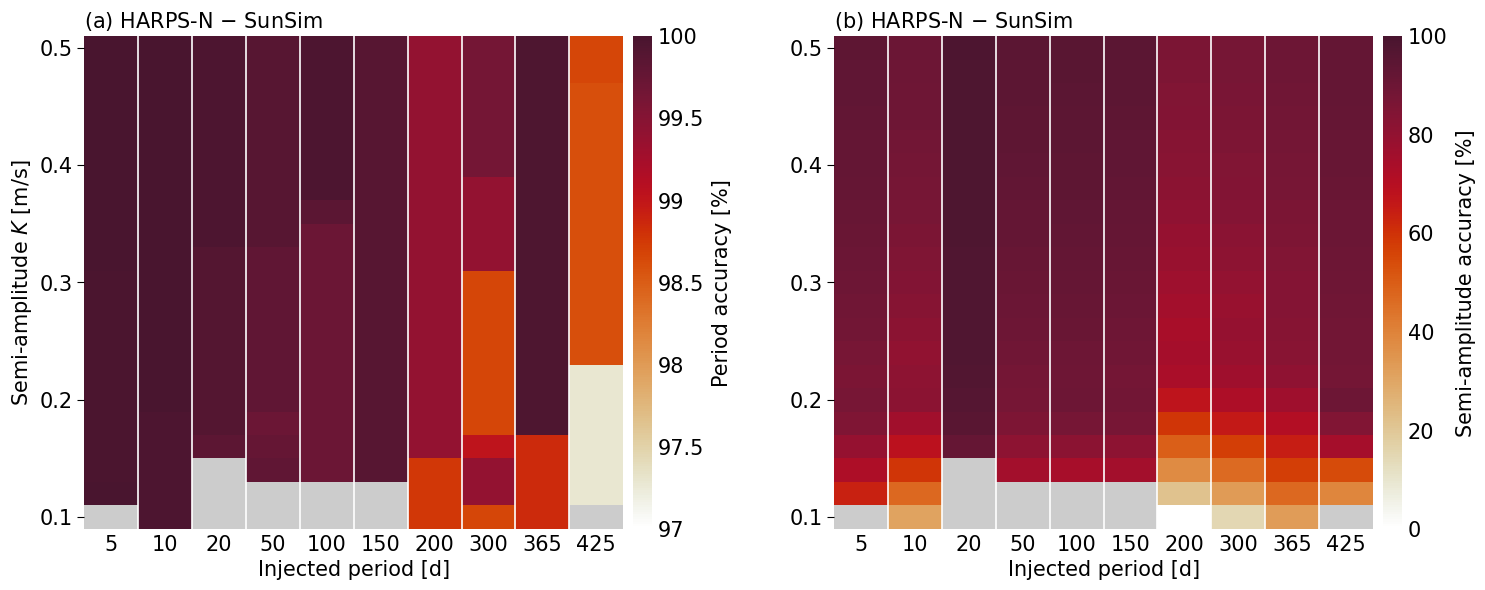

In [17]:
ACC_PANELS = [('dP', 'Period accuracy [%]', 97), ('dK%', 'Semi-amplitude accuracy [%]', 0)]   # key, label, colour-bar minimum


def plot_accuracy(k, name):
    # accuracy = 100 % - median |recovered - injected| / injected [%] of every (K, P), recovered injections only
    # (grey: none)
    with plt.rc_context({'xtick.direction': 'out', 'ytick.direction': 'out', 'xtick.top': False, 'ytick.right': False,
                         'xtick.major.size': 5, 'ytick.major.size': 5, 'axes.linewidth': 0.8}):
        n = len(ACC_PANELS)
        fig = plt.figure(figsize=(8.5 * n, 6.4))
        gs = fig.add_gridspec(1, 3 * n - 1, width_ratios=[1, 0.035, 0.3] * (n - 1) + [1, 0.035], wspace=0.04)
        axes = [fig.add_subplot(gs[0, 0])]
        axes += [fig.add_subplot(gs[0, 3 * i], sharex=axes[0], sharey=axes[0]) for i in range(1, n)]
        for i, (ax, (key, label, vmin)) in enumerate(zip(axes, ACC_PANELS)):
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', RuntimeWarning)          # nothing recovered: NaN
                m = 100 - np.nanmedian(np.abs(acc[k][key]), axis=2).T    # (n_amplitudes, n_periods)
            ax.set_xscale('function', functions=(fwd, inv))
            ax.set_facecolor('0.8')                                      # grey: nothing recovered
            im = ax.pcolormesh(edges_p, edges_k, np.ma.masked_invalid(m), cmap=CMAP, vmin=vmin, vmax=100,
                               rasterized=True)
            ax.vlines(edges_p[1:-1], edges_k[0], edges_k[-1], color='white', lw=1.2, zorder=2)   # column gaps
            ax.set_title('(%s) %s' % ('abcd'[i], models[k].name), loc='left', pad=6)
            ax.set_xticks(PERIODS_U, ['%.0f' % p for p in PERIODS_U])
            ax.xaxis.set_minor_locator(plt.NullLocator())
            ax.tick_params(axis='x', length=0, pad=4)
            ax.set_xlabel('Injected period [d]')
            ax.set_ylim(edges_k[0], edges_k[-1])
            ax.set_yticks(np.arange(0.1, 0.51, 0.1))
            for s in ax.spines.values():
                s.set_visible(False)
            cax = fig.add_subplot(gs[0, 3 * i + 1])
            cb = fig.colorbar(im, cax=cax, format='%g', extend='min' if np.nanmin(m) < vmin else 'neither')
            cb.set_label(label, labelpad=6)
            cb.outline.set_visible(False)
            cax.tick_params(length=0, pad=4)
        axes[0].set_xlim(edges_p[0], edges_p[-1])
        axes[0].set_ylabel('Semi-amplitude $K$ [$\\mathrm{m\\,s^{-1}}$]')
    save(fig, name)
    plt.show()


plot_accuracy('res', 'inj_baluev_accuracy_corrected')
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)
    for key, label, _ in ACC_PANELS:                                     # the values of the map
        m = 100 - np.nanmedian(np.abs(acc['res'][key]), axis=2).T
        show(pd.DataFrame(m[::-1], index=pd.Index(AMPLITUDES[::-1], name='K [m/s]'), columns=PERIODS_U.astype(int)),
             '%s: %s (median over the recovered injections; -: none recovered)'
             % (models['res'].name.replace('$-$', '-'), label),
             {c: '%.2f' if key == 'dP' else '%.1f' for c in PERIODS_U.astype(int)})


## Comparison with astropy (LombScargle, Baluev FAP)

In [9]:
from astropy.timeseries import LombScargle
from sunsim.planet import planet


def inject_astropy(y, dy, freq):
    # injection-recovery of section "Injection-recovery" with astropy: highest peak of LombScargle(T, y + planet, dy)
    # (method 'fast', same frequency grid) with FAP <= FAP (Baluev, astropy) and its period within PERIOD_TOL
    level = LombScargle(T, y, dy).false_alarm_level(FAP, method='baluev', maximum_frequency=freq[-1])
    out = np.zeros((len(AMPLITUDES), len(PERIODS_U)))
    for j, P in enumerate(PERIODS_U):
        units = [planet.keplerian_orbit(T, [P, 1.0, 0.0, 0.0, t0]) for t0 in T[0] + P * np.arange(N_PHASES) / N_PHASES]
        for i, K in enumerate(AMPLITUDES):
            for u in units:
                p = LombScargle(T, y + K * u, dy).power(freq, method='fast')
                k = p.argmax()
                out[i, j] += (p[k] >= level) & (np.abs(1 / freq[k] - P) / P <= PERIOD_TOL)
    return 100 * out / N_PHASES, float(level)


for k, ra in models.items():
    p_ap = LombScargle(T, ra.y).power(ra.freq, method='cython')
    lv_ap = LombScargle(T, ra.y).false_alarm_level(FAP, method='baluev', maximum_frequency=ra.freq[-1])
    print('%-18s ours vs astropy: max |power difference| %.1e, power at FAP %g: %.6f vs %.6f'
          % (ra.name.replace('$-$', '-'), np.max(np.abs(spectra[k]['power'] - p_ap)), FAP, ra.power_level(FAP), lv_ap))

rate_ap = {}
for k, ra in models.items():
    p = LombScargle(T, ra.y).power(ra.freq, method='fast')
    rate_ap[k], level = inject_astropy(ra.y, None, ra.freq)
    top = np.argsort(p)[::-1]
    loc = [i for i in top[:200] if 0 < i < len(p) - 1 and p[i] >= p[i - 1] and p[i] >= p[i + 1] and p[i] >= level][:6]
    print('%-18s power at FAP %g: %.4f; significant peaks [d]: %s'
          % (ra.name.replace('$-$', '-'), FAP, level, ', '.join('%.1f' % (1 / ra.freq[i]) for i in loc) or 'none'))

HARPS-N            ours vs astropy: max |power difference| 9.6e-14, power at FAP 0.001: 0.015241 vs 0.015241
HARPS-N - SunSim   ours vs astropy: max |power difference| 1.9e-15, power at FAP 0.001: 0.015241 vs 0.015241
HARPS-N            power at FAP 0.001: 0.0152; significant peaks [d]: 26.4, 26.1, 13.3, 14.3, 25.9, 31.6
HARPS-N - SunSim   power at FAP 0.001: 0.0152; significant peaks [d]: 632.9, 500.2, 28.5, 838.1, 30.1


In [10]:
for k, ra in models.items():
    cols = {}
    for level in (50, 100):
        cols['ours K%d' % level] = k_limit(rate[k], level)
        cols['astropy K%d' % level] = k_limit(rate_ap[k], level)
    cols['max |ours - astropy| [%]'] = np.abs(rate[k] - rate_ap[k]).max(axis=0)
    show(pd.DataFrame(cols, index=pd.Index(PERIODS_U.astype(int), name='P [d]')),
         '%s: K [m/s] at 50 and 100 %% recovered (-: not reached up to %.1f m/s)'
         % (ra.name.replace('$-$', '-'), AMPLITUDES[-1]), {'max |ours - astropy| [%]': '%.0f'})


HARPS-N: K [m/s] at 50 and 100 % recovered (-: not reached up to 0.5 m/s)
       ours K50  astropy K50  ours K100  astropy K100 max |ours - astropy| [%]
P [d]                                                                         
5          0.50         0.50          -             -                        2
10         0.50         0.50          -             -                        1
20         0.50         0.50          -             -                        0
50         0.46         0.46          -             -                        0
100        0.48         0.48          -             -                        0
150        0.46         0.46          -             -                        0
200        0.50         0.50          -             -                        0
300        0.48         0.48          -             -                        0
365        0.46         0.46          -             -                        0
425        0.40         0.40          -             -    

## Article figure: periodograms

(a) HARPS-N: 17 peaks with FAP <= 0.001, power level 0.0152
(b) HARPS-N - SunSim: 5 peaks with FAP <= 0.001, power level 0.0152


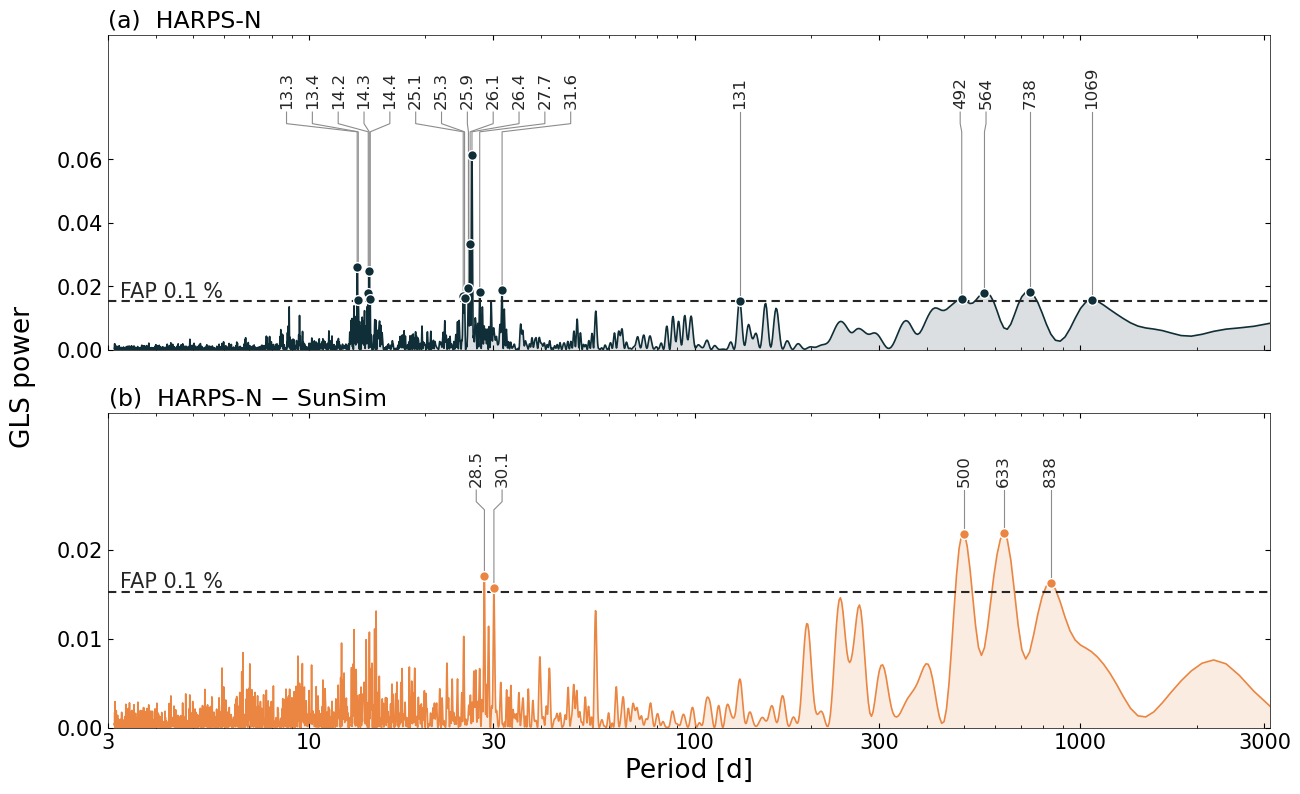

In [11]:
from matplotlib.ticker import FixedLocator

ART_XLIM = (3, np.ptp(T))                     # periods up to the time span


def spread(x, gap, lo, hi):
    # 1D label placement: positions closest to x (sorted) with a minimum gap, inside [lo, hi]
    blocks = [[xi, [i]] for i, xi in enumerate(x)]
    merged = True
    while merged:
        merged = False
        for b in blocks:
            n = len(b[1])
            b[0] = np.clip(np.mean([x[i] for i in b[1]]), lo + gap * (n - 1) / 2, hi - gap * (n - 1) / 2)
        for j in range(len(blocks) - 1):
            a, b = blocks[j], blocks[j + 1]
            if a[0] + gap * len(a[1]) / 2 > b[0] - gap * len(b[1]) / 2 - 1e-9:
                blocks[j:j + 2] = [[0, a[1] + b[1]]]
                merged = True
                break
    out = np.empty(len(x))
    for c, m in blocks:
        out[m] = c + gap * (np.arange(len(m)) - (len(m) - 1) / 2)
    return out


def label_peaks(ax, P, power, colour, y_elbow, y_text, fs=12):
    # every peak: marker, leader line and its period on a common row above the curve
    o = np.argsort(P)
    P, power = np.asarray(P)[o], np.asarray(power)[o]
    ax.figure.canvas.draw()
    xd = ax.transData.transform(np.c_[P, power])[:, 0]
    gap = fs * 1.55 * ax.figure.dpi / 72
    x0, x1 = ax.transData.transform([(ART_XLIM[0], 1), (ART_XLIM[1], 1)])[:, 0]
    Pl = ax.transData.inverted().transform(np.c_[spread(xd, gap, x0 + gap, x1 - gap), np.zeros_like(xd)])[:, 0]
    y_bend = y_elbow + 0.35 * (y_text - y_elbow)
    for p, z, pl in zip(P, power, Pl):
        ax.plot([p, p, pl, pl], [z, y_elbow, y_bend, y_text * 0.985], color='0.55', lw=0.8, zorder=1)
        ax.text(pl, y_text, '%.1f' % p if p < 100 else '%.0f' % p, rotation=90, ha='center', va='bottom',
                fontsize=fs, color='0.15')
    ax.plot(P, power, 'o', ms=7, mfc=colour, mec='white', mew=1, zorder=4)


art = {k: models[k] for k in SERIES}
ART_COLOURS = {'obs': obs.COLOURS['harpsn'], 'res': obs.COLOURS['sim']}   # colours of the TSI and RV figure (10_years)
rc = {'font.size': 15, 'axes.labelsize': 19, 'axes.titlesize': 17, 'xtick.labelsize': 15, 'ytick.labelsize': 15,
      'legend.fontsize': 17, 'axes.linewidth': 0.5, 'xtick.direction': 'in', 'ytick.direction': 'in',
      'xtick.top': True, 'ytick.right': True, 'lines.linewidth': 2.2}       # style of the TSI and RV figure (10_years)
with plt.rc_context(rc):
    fig, axes = plt.subplots(len(art), 1, figsize=(15, 9), sharex=True, gridspec_kw={'hspace': 0.2})
    for i, (ax, (k, ra)) in enumerate(zip(axes, art.items())):
        name, colour = SERIES[k][0], ART_COLOURS[k]
        sp = spectrum(ra)
        pk = local_peaks(ra, sp)
        top = sp['power'].max()
        m = (sp['P'] >= ART_XLIM[0]) & (sp['P'] <= ART_XLIM[1])
        ax.fill_between(sp['P'][m], 0, sp['power'][m], color=colour, alpha=0.15, lw=0, zorder=1)
        ax.plot(sp['P'][m], sp['power'][m], color=colour, lw=1.2, zorder=2)
        level = ra.power_level(FAP)
        ax.axhline(level, color='0.15', lw=1.5, ls=(0, (4, 2.5)), zorder=3)
        ax.text(ART_XLIM[0] * 1.08, level, 'FAP %g %%' % (100 * FAP), ha='left', va='bottom', fontsize=15,
                color='0.15')
        ax.set_title('(%s)  %s' % ('ab'[i], name), loc='left', pad=5)
        ax.set_xscale('log')
        ax.set_xlim(*ART_XLIM)
        ax.set_ylim(0, top * 1.62)
        ax.yaxis.set_major_locator(FixedLocator(np.arange(0, top * 1.3, 0.01 if top < 0.03 else 0.02)))
        label_peaks(ax, pk['P [d]'].to_numpy(), pk['power'].to_numpy(), colour, top * 1.12, top * 1.24)
        print('(%s) %s: %d peaks with FAP <= %g, power level %.4f'
              % ('ab'[i], name.replace('$-$', '-'), len(pk), FAP, level))
    axes[-1].xaxis.set_major_locator(FixedLocator([3, 10, 30, 100, 300, 1000, 3000]))
    axes[-1].set_xticklabels(['3', '10', '30', '100', '300', '1000', '3000'])
    axes[-1].set_xlabel('Period [d]')
    fig.supylabel('GLS power', x=0.06, fontsize=19)
    if FIGURES:
        fig.savefig(os.path.join(FIGURES, 'gls_peaks.pdf'), bbox_inches='tight')
    plt.show()